# Custom bundle adjustment on a synthetic block

`pycolmap_ba` adds three kinds of residual blocks to **COLMAP's own** bundle-adjustment problem, the same Ceres problem COLMAP builds for its tie points:

| Block | Input | What it contributes |
|---|---|---|
| **Markers** (GCPs) | image marks of targets + their surveyed coordinates | the datum; markers left out of control become *check points*, an unbiased accuracy estimate |
| **Camera poses** | GNSS camera centres, optionally INS attitudes | the datum, from the cameras' side |
| **Reference cloud** | a georeferenced LiDAR / TLS point cloud | the datum *and* the block's shape, but only if the scanned surfaces face in varied directions |

This notebook builds a synthetic block with pycolmap, where the truth is known exactly, and walks through:

1. how the synthetic dataset is made, and how a pycolmap reconstruction is organised;
2. how to build each of the three inputs;
3. why a plain bundle cannot fix a block that is in the wrong place;
4. one custom bundle with all three blocks, and how to read its result.

Needs the `examples` extra: `uv sync --extra examples`, or `EXTRAS=examples` for the Docker image.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pycolmap

from pycolmap_ba import (
    CameraPoseConstraints,
    GroundTruth,
    MarkerConstraints,
    ReferenceCloud,
    ReferenceCloudConstraints,
    SolverOptions,
    accuracy_report,
    run_bundle_adjustment,
    run_cloud_constrained_bundle_adjustment,
)
from pycolmap_ba.core import datum_information
from pycolmap_ba.utils import camera_center_rmse, rotation_error_deg
from pycolmap_ba.utils.compatibility import CompatibilityOptions
from pycolmap_ba.utils.perturb import Perturbation, perturb_reconstruction

rng = np.random.default_rng(0)

## 1. The synthetic dataset

`pycolmap.synthesize_dataset` generates a complete, self-consistent reconstruction: cameras, poses, 3D points, and the 2D keypoints those points project to. Nothing is estimated, so every number in it is *the truth*.

Here: one rig with one camera, 8 frames (capture instants), 300 points. Seeding pycolmap makes it reproducible.

In [8]:
pycolmap.set_random_seed(0)
truth = pycolmap.synthesize_dataset(
    pycolmap.SyntheticDatasetOptions(
        num_rigs=1, num_cameras_per_rig=1, num_frames_per_rig=8, num_points3D=1000
    )
)
print(truth.summary())

Reconstruction:
	num_rigs = 1
	num_cameras = 1
	num_frames = 8
	num_reg_frames = 8
	num_images = 8
	num_points3D = 1000
	num_observations = 8000
	mean_track_length = 8
	mean_observations_per_image = 1000
	mean_reprojection_error = 6.26984e-14


### Cameras: the intrinsics

All 8 images share one camera. `SIMPLE_RADIAL` has a single focal length, the principal point and one radial distortion coefficient. `params` is a flat vector, and `params_info` names its entries.

In [9]:
camera = truth.cameras[1]
print(f"{camera.model.name}, {camera.width} x {camera.height} px")
print(dict(zip(camera.params_info.split(", "), camera.params, strict=True)))

SIMPLE_RADIAL, 1024 x 768 px
{'f': np.float64(1280.0), 'cx': np.float64(512.0), 'cy': np.float64(384.0), 'k': np.float64(0.05)}


### Rigs, frames and images: the poses

Since COLMAP 3.12 the data model has three levels:

- a **rig** describes a sensor layout (here a single camera);
- a **frame** is one capture instant of a rig and holds its pose `rig_from_world`;
- an **image** is what one camera of the frame recorded; `image.cam_from_world()` combines the frame pose with the camera's offset inside the rig.

With one camera per rig the two poses coincide. That matters for `pycolmap_ba`: its marker and 6-DoF pose blocks act on the frame's `rig_from_world` parameters directly, which is why they refuse multi-camera rigs.

A pose maps world to camera coordinates, `x_cam = R x_world + t`, so the camera **centre** is `C = -R^T t` (`projection_center()`), and the viewing direction is the third row of `R`. In this dataset the cameras sit about 5 units out and look at the centre of the point cloud.

In [10]:
rows = []
for image in sorted(truth.images.values(), key=lambda im: im.name):
    rotation = image.cam_from_world().rotation.matrix()
    rows.append({
        "image": image.name,
        "image_id": image.image_id,
        "frame_id": image.frame_id,
        "centre": image.projection_center().round(2),
        "looks along": rotation[2].round(2),
        "points seen": image.num_points3D,
    })
pd.DataFrame(rows)

,image,image_id,frame_id,centre,looks along,points seen
0,camera000001_frame000000.png,1,1,"[1.17, -3.15, 3.7]","[-0.23, 0.63, -0.74]",1000
1,camera000001_frame000001.png,2,2,"[-0.27, 2.66, 4.22]","[0.05, -0.53, -0.84]",1000
2,camera000001_frame000002.png,3,3,"[3.5, 2.08, 2.9]","[-0.7, -0.42, -0.58]",1000
3,camera000001_frame000003.png,4,4,"[-0.84, 1.61, 4.66]","[0.17, -0.32, -0.93]",1000
4,camera000001_frame000004.png,5,5,"[3.5, 3.44, 0.99]","[-0.7, -0.69, -0.2]",1000
5,camera000001_frame000005.png,6,6,"[3.54, 3.08, 1.73]","[-0.71, -0.62, -0.35]",1000
6,camera000001_frame000006.png,7,7,"[-0.65, -0.28, 4.95]","[0.13, 0.06, -0.99]",1000
7,camera000001_frame000007.png,8,8,"[0.34, -1.62, -4.72]","[-0.07, 0.32, 0.94]",1000


### Points and tracks: the observations

Each 3D point stores its coordinates and a **track**: the list of `(image_id, point2D_idx)` observing it. Each image stores its keypoints (`points2D`), and each keypoint links back to its 3D point. Every point here is seen by all 8 images.

Because nothing was measured, projecting a point reproduces its keypoints to machine precision.

In [11]:
point = next(iter(truth.points3D.values()))
print(f"point at {point.xyz.round(3)}, track length {point.track.length()}")
for element in point.track.elements[:3]:
    image = truth.images[element.image_id]
    keypoint = image.points2D[element.point2D_idx].xy
    error = np.linalg.norm(image.project_point(point.xyz) - keypoint)
    print(f"  {image.name}: keypoint {keypoint.round(2)} px, error {error:.1e} px")
mean_error = truth.compute_mean_reprojection_error()
print(f"mean reprojection error of the block: {mean_error:.1e} px")

point at [ 0.635  0.669 -0.386], track length 8
  camera000001_frame000000.png: keypoint [694.4  441.18] px, error 5.7e-14 px
  camera000001_frame000001.png: keypoint [708.58 219.47] px, error 0.0e+00 px
  camera000001_frame000002.png: keypoint [272.31 325.16] px, error 0.0e+00 px
mean reprojection error of the block: 6.3e-14 px


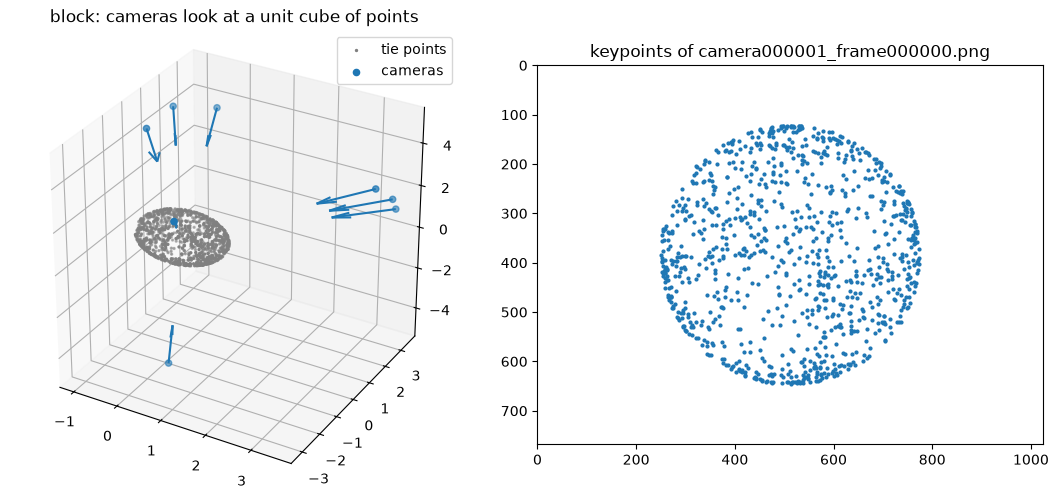

In [15]:
truth_xyz = np.array([p.xyz for p in truth.points3D.values()])
truth_centres = {im.name: im.projection_center() for im in truth.images.values()}

fig = plt.figure(figsize=(11, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.scatter(*truth_xyz.T, s=2, c="0.5", label="tie points")
for image in truth.images.values():
    centre = image.projection_center()
    direction = image.cam_from_world().rotation.matrix()[2]
    ax.quiver(*centre, *direction, length=1.5, color="tab:blue")
ax.scatter(*np.array(list(truth_centres.values())).T, c="tab:blue", label="cameras")
ax.set_box_aspect((1, 1, 1))
ax.set_title("block: cameras look at a unit cube of points")
ax.legend()

image = truth.images[1]
uv = np.array([p.xy for p in image.points2D if p.has_point3D()])
ax2 = fig.add_subplot(1, 2, 2)
ax2.scatter(*uv.T, s=4)
ax2.set_xlim(0, camera.width)
ax2.set_ylim(camera.height, 0)
ax2.set_aspect("equal")
ax2.set_title(f"keypoints of {image.name}")
plt.tight_layout()
plt.show()

### Making it realistic: keypoint noise

Real keypoints are not exact. `synthesize_noise` adds Gaussian noise to them, here 0.5 px per axis, on the copy we will adjust; `truth` stays exact. The mean reprojection error becomes the mean of a Rayleigh distribution, `0.5 * sqrt(pi / 2) = 0.63 px`.

In [17]:
block = pycolmap.Reconstruction(truth)
pycolmap.synthesize_noise(pycolmap.SyntheticNoiseOptions(point2D_stddev=0.5), block)
print(f"mean reprojection error: {block.compute_mean_reprojection_error():.3f} px")

mean reprojection error: 0.626 px


## 2. The inputs

All three constraint types take plain Python data (dicts, a DataFrame, an array), so they are dataset-agnostic. Every sigma is given in its **native unit** (pixels, metres, degrees); `pycolmap_ba` converts them into one consistent weighting relative to `tie_points_sigma_px`.

### 2a. Markers (GCPs)

Six targets, placed at the face centres of the point cube. A marker contributes two things:

- its **image marks**: here the exact projections plus 0.3 px noise, as a hand-measured target would be;
- its **surveyed coordinate**: here the truth plus 5 mm noise.

Only markers listed in `control_names` get their coordinate constrained. The others are **check points**: triangulated from their marks but never pulled towards their survey, so their final error is an honest accuracy estimate.

In [19]:
marker_true = {
    f"M{i}": xyz for i, xyz in enumerate(np.vstack([np.eye(3), -np.eye(3)]) * 0.8)
}
control_names = ["M0", "M1", "M2"]
check_names = ["M3", "M4", "M5"]

marks = []
for image in truth.images.values():
    for name, xyz in marker_true.items():
        u, v = image.project_point(xyz) + rng.normal(0.0, 0.3, 2)
        marks.append((image.name, name, u, v))
marker_obs = pd.DataFrame(marks, columns=["image_name", "marker_name", "u", "v"])
marker_survey = {
    name: xyz + rng.normal(0.0, 0.005, 3) for name, xyz in marker_true.items()
}

markers = MarkerConstraints(
    observations=marker_obs,
    xyz=marker_survey,
    control_names=control_names,
    sigma_px=0.3,
    sigma_m=0.005,
)
marker_obs.head()

,image_name,marker_name,u,v
0,camera000001_frame000007.png,M0,719.022890,386.096749
1,camera000001_frame000007.png,M1,514.611615,568.589545
2,camera000001_frame000007.png,M2,524.218736,326.674635
3,camera000001_frame000007.png,M3,309.835344,381.978566
4,camera000001_frame000007.png,M4,509.597740,178.984108


### 2b. Camera poses (GNSS / INS)

`positions` are prior camera **centres** in world coordinates, here the truth plus 2 cm noise. This alone reproduces COLMAP's native position priors.

Adding `sigma_rot_deg` with full prior poses (`cam_from_world`) also constrains the attitudes, which COLMAP's native priors cannot. Here the prior rotations carry 0.02 deg of noise. A prior pose is built from its rotation and its centre, since the translation is `t = -R C`. When `sigma_rot_deg` is set, the positions are taken from these poses.

In [20]:
gnss = {name: c + rng.normal(0.0, 0.02, 3) for name, c in truth_centres.items()}


def noisy_pose(
    image: pycolmap.Image, centre: np.ndarray, sigma_deg: float
) -> pycolmap.Rigid3d:
    tilt = pycolmap.Rotation3d(np.deg2rad(rng.normal(0.0, sigma_deg, 3)))
    rotation = tilt * image.cam_from_world().rotation
    return pycolmap.Rigid3d(rotation, -rotation.matrix() @ centre)


ins = {im.name: noisy_pose(im, gnss[im.name], 0.02) for im in truth.images.values()}
camera_poses = CameraPoseConstraints(
    positions=gnss, cam_from_world=ins, sigma_m=0.02, sigma_rot_deg=0.02
)

### 2c. The reference cloud (LiDAR / TLS)

A scanner samples *surfaces*. To simulate that, each tie point gets a small flat disc of 30 samples (1 cm radius) through it, with a random orientation: every tie point lies exactly on a scanned surface element.

`ReferenceCloud.from_points` fits a local plane to the 20 nearest neighbours of every sample and turns it into a covariance that is **stiff across** the surface (`sigma_ref`, the scanner accuracy, 2 mm here) and **slack along** it (`sigma_slack`). A tie point is then pulled *onto* the surface but free to slide along it, which is the right model: its true counterpart lies somewhere on the surface, not at the nearest sample.

In [21]:
def planar_patches(centres, normals, radius=0.01, n=30):
    discs = []
    for centre, normal in zip(centres, normals, strict=True):
        u = np.cross(normal, np.eye(3)[np.argmin(np.abs(normal))])
        u /= np.linalg.norm(u)
        v = np.cross(normal, u)
        r = radius * np.sqrt(rng.random(n))
        theta = 2 * np.pi * rng.random(n)
        discs.append(
            centre + np.outer(r * np.cos(theta), u) + np.outer(r * np.sin(theta), v)
        )
    return np.vstack(discs)


normals = rng.normal(size=truth_xyz.shape)
normals /= np.linalg.norm(normals, axis=1, keepdims=True)
cloud = ReferenceCloud.from_points(planar_patches(truth_xyz, normals), sigma_ref=0.002)

print(f"{len(cloud):,} reference points")
print(f"sample 0: normal {cloud.normals[0].round(3)}")
print(f"sample 0: roughness {cloud.roughness[0]:.1e} m")
# Sigmas in ascending order: across the surface, then the two along it.
print(f"sample 0: constraint sigmas {cloud.sigmas()[0].round(4)} m")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
30,000 reference points
sample 0: normal [-0.023  0.501  0.865]
sample 0: roughness 6.0e-11 m
sample 0: constraint sigmas [2.0000e-03 1.8402e+00 1.0000e+01] m


**Does the cloud fix the whole datum?** A similarity has 7 degrees of freedom: 3 translations, 3 rotations, scale. A surface only constrains motion *across* it, so which of the 7 the cloud fixes depends on how its surfaces are oriented, not on how dense it is. `datum_information` measures it: per mode, how far the block could still move at its edge.

With randomly oriented patches every mode is pinned. With the same cloud made **flat** (every normal vertical, like an aerial scan of open ground), easting, northing and yaw (`tx`, `ty`, `rz`) are free: the block can slide and spin on the ground without crossing any surface.

In [22]:
def observability(cloud: ReferenceCloud) -> None:
    idx, _ = cloud.query(truth_xyz, 0.05)
    print(datum_information(truth_xyz, cloud.covariances(idx)).summary(threshold=0.001))


observability(cloud)
flat = np.tile([0.0, 0.0, 1.0], (len(truth_xyz), 1))
observability(
    ReferenceCloud.from_points(planar_patches(truth_xyz, flat), sigma_ref=0.002)
)

datum observability (about centroid, L = 1.0 m)
  sigma    0.0001 m  mostly    ry  (0.63)
  sigma    0.0001 m  mostly    rz  (0.78)
  sigma    0.0001 m  mostly    ry  (0.69)
  sigma    0.0001 m  mostly    tx  (0.64)
  sigma    0.0001 m  mostly    ty  (0.80)
  sigma    0.0001 m  mostly    tz  (0.63)
  sigma    0.0001 m  mostly scale  (0.73)
datum observability (about centroid, L = 1.0 m)
  sigma    0.0030 m  mostly    rz  (0.82)  <-- WEAK
  sigma    0.0026 m  mostly    ty  (0.86)  <-- WEAK
  sigma    0.0021 m  mostly    tx  (0.97)  <-- WEAK
  sigma    0.0001 m  mostly    ry  (0.84)
  sigma    0.0001 m  mostly scale  (0.89)
  sigma    0.0001 m  mostly    rx  (0.80)
  sigma    0.0001 m  mostly    tz  (1.00)


## 3. Knock the block out of place

Apply a 7-DoF similarity to the whole block, points and cameras together: 3 cm shift, 0.5 deg rotation, 0.5 % scale. This is exactly the *gauge freedom* of a free network: every reprojection residual stays the same, so the tie points cannot see it and cannot undo it. Whatever the adjustment recovers below is due to the added constraints alone.

The perturbation is kept small because of the reference cloud: its correspondence search needs the block within reach of the right surface. `reach` is how far the block edge moved; the first correspondence gate must exceed it.

In [23]:
report = perturb_reconstruction(
    block, Perturbation(shift_m=0.03, rot_deg=0.5, scale_ppm=5_000, seed=1)
)
print(report.summary())
mean_error = block.compute_mean_reprojection_error()
print(f"mean reprojection error: {mean_error:.3f} px (unchanged)")
centre_mm = camera_center_rmse(block, truth_centres) * 1000
print(f"camera centre RMSE vs truth: {centre_mm:.1f} mm")

perturbation applied
  datum      : 0.030 m translation, scale +5000 ppm
  reach      : 0.044 m at the block edge (L = 1 m) <- first gate must exceed this
mean reprojection error: 0.626 px (unchanged)
camera centre RMSE vs truth: 68.4 mm


## 4. A plain bundle cannot fix this

`run_bundle_adjustment` with no constraints is COLMAP's global bundle adjustment. With nothing tying the block to the world, it fixes the gauge on two cameras and refines the *shape* only. The block stays where it was put.

In [24]:
plain = pycolmap.Reconstruction(block)
solver = SolverOptions(refine_focal_length=False)
run_bundle_adjustment(plain, solver=solver, verbose=False)
centre_mm = camera_center_rmse(plain, truth_centres) * 1000
print(f"camera centre RMSE vs truth after a plain bundle: {centre_mm:.1f} mm")

camera centre RMSE vs truth after a plain bundle: 67.5 mm


## 5. The custom bundle: markers + camera poses + reference cloud

`run_cloud_constrained_bundle_adjustment` alternates two steps, like ICP:

1. find, for each tie point, its reference patch within the gate `max_dist`, then freeze those correspondences;
2. solve one bundle (`run_bundle_adjustment`) with every block in the same Ceres problem.

It repeats until the correspondences stop changing. `max_dist_schedule` opens the gate wide for the first pass and tightens it afterwards. Every other keyword (`markers`, `camera_poses`, `solver`, ...) is passed through to each solve.

Before solving it runs a compatibility check, to make sure the block sits close enough to the cloud. Its `cell_m` is the grid size of the footprint test; the 10 m default suits aerial blocks, but this whole block is 2 m across, so it is set to a few tie-point spacings.

`tie_points_sigma_px = 0.5` states the keypoint accuracy; every other sigma is weighted relative to it.

In [25]:
tie_sigma = 0.5
result = run_cloud_constrained_bundle_adjustment(
    block,
    cloud,
    solver=solver,
    markers=markers,
    camera_poses=camera_poses,
    reference_options=ReferenceCloudConstraints(max_dist=0.05),
    max_dist_schedule=[0.1, 0.05],
    compatibility=CompatibilityOptions(max_dist=0.1, cell_m=0.25),
    tie_points_sigma_px=tie_sigma,
)

tie points      : sigma 0.5 px  (reference unit)
marker image obs: sigma 0.3 px -> 0.60 in tie units
marker world    : sigma 0.005 m -> 0.01 in tie units
camera positions: sigma 0.02 m -> 0.04 in tie units
camera rotations: sigma 0.02 deg
gauge           : None
  reference cloud: 1,000 / 1,000 points constrained | to plane: median 0.014 m, p95 0.031 m | to sample: median 0.023 m
  problem: 9,059 blocks = 8,000 tie points + 1059 added (48 marker image, 3 marker world, 8 camera pose, 1000 reference cloud)
  solve 1: BundleAdjustmentTerminationType.CONVERGENCE
  pass 0: 1,000 constrained at 0.1 m gate, 100.0% correspondences changed, 0.1 s
tie points      : sigma 0.5 px  (reference unit)
marker image obs: sigma 0.3 px -> 0.60 in tie units
marker world    : sigma 0.005 m -> 0.01 in tie units
camera positions: sigma 0.02 m -> 0.04 in tie units
camera rotations: sigma 0.02 deg
gauge           : None
  reference cloud: 1,000 / 1,000 points constrained | to plane: median 0.001 m, p95 0.002 m |

## 6. Reading the result

**What was solved.** `n_blocks` counts the residual blocks by kind, all in one problem. `passes` shows the outer loop converging: the share of correspondences that changed drops to zero.

In [26]:
print(result.n_blocks)
columns = ["pass", "max_dist", "n_used", "changed_fraction", "median_surface_distance"]
pd.DataFrame(result.passes)[columns]

{'tie_points': 8000, 'marker_image': 48, 'marker_world': 3, 'camera_pose': 8, 'reference_cloud': 1000}


,pass,max_dist,n_used,changed_fraction,median_surface_distance
0,0,0.10,1000,1.000,0.013628
1,1,0.05,1000,0.998,0.000566
2,2,0.05,1000,0.224,0.000517
3,3,0.05,1000,0.001,0.000516


**Is the weighting right?** `result.residuals(group)` returns Ceres's whitened residuals per block. Divided by `tie_points_sigma_px` they are in units of their own sigma, so a well-weighted group has an RMS near 1. The reference-cloud group sits well below 1 for two reasons: two of its three axes run along the surface, where the constraint is deliberately slack and the residual is near zero; and across the surface the tie points are off by their own triangulation noise (under a millimetre here), less than the 2 mm scanner sigma.

The **variance factor** sigma0 summarises the whole adjustment: `ratio` = 1 means the stated sigmas match the actual residuals. That is what licenses reading the posterior covariances (`result.point_covariances()`, etc.) as real accuracies.

In [27]:
for group in ["marker_image", "marker_world", "camera_pose", "reference_cloud"]:
    whitened = result.residuals(group) / tie_sigma
    rms = np.sqrt(np.mean(whitened**2))
    print(f"{group:16s} {len(whitened):4d} blocks, RMS {rms:.2f} sigma")

vf = result.variance_factor(tie_points_sigma_px=tie_sigma)
print(f"\nsigma0 = {vf.sigma0:.3f} px, ratio to the assumed sigma = {vf.ratio:.2f}")

marker_image       48 blocks, RMS 0.85 sigma
marker_world        3 blocks, RMS 0.91 sigma
camera_pose         8 blocks, RMS 1.16 sigma
reference_cloud  1000 blocks, RMS 0.21 sigma

sigma0 = 0.454 px, ratio to the assumed sigma = 0.91


**How accurate is it?** Against the known truth. The check points are the honest number: they were never constrained, so their error measures the whole chain. The camera rows are flagged as a fit, since the cameras were given priors.

In [28]:
accuracy_report(
    block,
    result.marker_xyz,
    GroundTruth(
        camera_xyz=truth_centres,
        marker_xyz=marker_true,
        control_names=control_names,
        check_names=check_names,
        cam_from_world={im.name: im.cam_from_world() for im in truth.images.values()},
    ),
    label="all three blocks",
    camera_priors_used=True,
    result=result,
)


ACCURACY vs GROUND TRUTH - all three blocks
                                bias E   bias N   bias U    RMSE 3D     n     NMAD
                                  (cm)     (cm)     (cm)       (cm)           (cm)
  camera centres n=8             +0.02    -0.02    -0.01       0.10     8     0.04   (fit - priors used)
  control (GCP) n=3              +0.00    +0.03    -0.04       0.10     3     0.04   (fit - always flattering)
  check (CP) n=3                 -0.00    +0.00    -0.03       0.09     3     0.00   <- TRUE ACCURACY

  camera rotations       mean 0.0128 deg   max 0.0200 deg


In [ ]:
truth_images = {im.name: im for im in truth.images.values()}
rotation_errors = [
    rotation_error_deg(
        im.cam_from_world().rotation.matrix(),
        truth_images[im.name].cam_from_world().rotation.matrix(),
    )
    for im in block.images.values()
]
centre_mm = camera_center_rmse(block, truth_centres) * 1000
print(
    f"camera centres: {centre_mm:.2f} mm RMSE (edge moved {report.reach * 1000:.0f} mm)"
)
print(f"camera rotations: max error {max(rotation_errors):.4f} deg")
for name in check_names:
    error = np.linalg.norm(result.marker_xyz[name] - marker_true[name])
    print(f"check point {name}: {error * 1000:.2f} mm")

## Takeaways

- The three blocks share **one** Ceres problem with COLMAP's tie points; `n_blocks` shows the composition and `run_bundle_adjustment` asserts nothing got orphaned.
- A similarity offset is invisible to the tie points: only the constraints fix the datum. A plain bundle leaves the block where it was.
- Markers need their **check points** to say anything about accuracy; control markers only show a fit.
- Camera **position** priors constrain the centre `C = -R^T t` in world axes; **rotation** priors add the attitude, which also fixes the datum where positions alone cannot (e.g. two cameras, or cameras along a line).
- A reference cloud fixes the datum only through the **orientation diversity** of its surfaces: check `datum_information` before trusting it. A flat scan leaves easting, northing and yaw free however dense it is.
- Weights are stated in native units; `sigma0` near 1 confirms they are consistent with the data.

The same calls work on a real block: replace the synthetic inputs with marker marks and a survey, GNSS/INS poses, and a LiDAR cloud. The `enrich/` notebooks do exactly that on the ENRICH aerial dataset.